# Adapted complex SwinMR-PI at 2×, 4×, 6×, and 8×

This notebook reports four separately trained 50-epoch models. For each rate,
epochs 10, 20, 30, 40, and 50 were screened on validation data before one
evaluation of the selected checkpoint on the 14-volume held-out test split.

The official SwinMR backbone and composite image/frequency/perceptual objective
are retained. The implementation adapts the network to two-channel complex brain
MRI, supplied sensitivity maps, variable coil counts, and the project's frozen
Cartesian masks. It does **not** add a data-consistency layer.

Reference: [official repository](https://github.com/ayanglab/SwinMR)

In [1]:
from pathlib import Path
from html import escape
import json, os, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_ROOT = Path(os.environ.get('MRI_DATA_ROOT', '/data/david_agyei/nyu-dataset'))
OUTPUT_ROOT = Path(os.environ.get('SWINMR_OUTPUT_ROOT', DATA_ROOT/'derived'))
RATES = (2, 4, 6, 8)
def read_json(path): return json.loads(Path(path).read_text())
def artifacts(rate):
    run = OUTPUT_ROOT/f'swinmr_pi_complex_{rate}x'; evaluation = run/'evaluation'
    selection = read_json(evaluation/'best_validation_checkpoint.json')
    test_dir = evaluation/'test'/f"step-{selection['checkpoint_step']:07d}"
    return run, selection, test_dir, read_json(test_dir/'summary.json')
def show_table(rows, columns, precision=4, bold_best=None):
    bold_best = bold_best or {}; best = {}
    for key, direction in bold_best.items():
        values = [row[key] for row in rows if isinstance(row[key], (int,float)) and np.isfinite(row[key])]
        best[key] = (max if direction == 'max' else min)(values)
    def render(value): return f'{value:.{precision}f}' if isinstance(value,float) else escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for key,label in columns)
    def cell(row,key):
        value=render(row[key])
        if key in best and np.isclose(row[key],best[key]): value=f'<strong>{value}</strong>'
        return f'<td style="padding:4px 10px">{value}</td>'
    body=''.join('<tr>'+''.join(cell(row,key) for key,label in columns)+'</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

runs = {rate: artifacts(rate) for rate in RATES}
figure_metadata = read_json(ROOT/'results/swinmr_evaluation/qualitative/all_rate_comparison.json')

## Validation selection

Rate,Selected epoch,Step,Validation PSNR,Validation SSIM
2×,50,11950,39.0670,0.9558
4×,50,11950,33.4191,0.8968
6×,50,11950,30.3100,0.8506
8×,50,11950,28.4968,0.8192


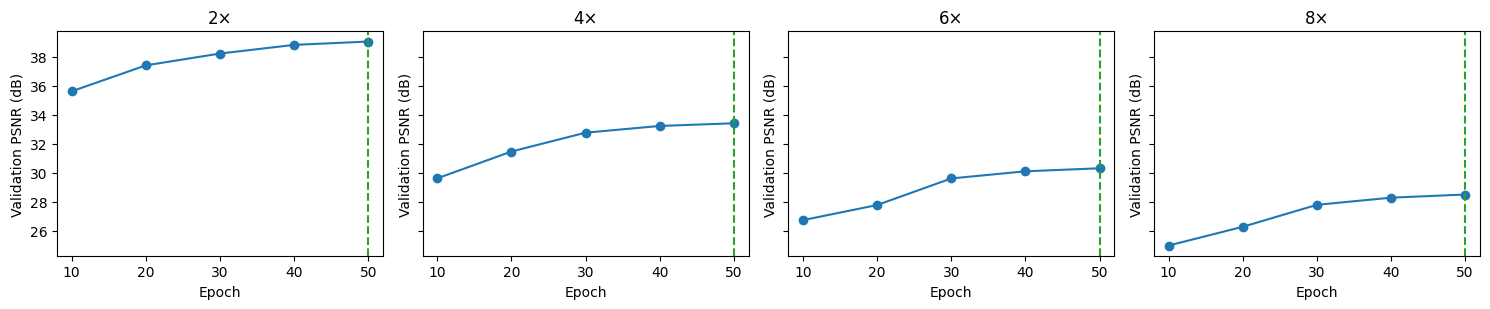

In [2]:
rows=[]
fig,axes=plt.subplots(1,4,figsize=(15,3.2),sharey=True)
for axis,rate in zip(axes,RATES):
    selection=runs[rate][1]
    candidates=selection['candidates']
    rows.append({'Rate':f'{rate}×','Selected epoch':selection['completed_epochs'],
                 'Step':selection['checkpoint_step'],'Validation PSNR':selection['validation_metrics']['psnr'],
                 'Validation SSIM':selection['validation_metrics']['ssim']})
    axis.plot([x['completed_epochs'] for x in candidates],[x['swinmr']['psnr'] for x in candidates],marker='o')
    axis.axvline(selection['completed_epochs'],color='tab:green',linestyle='--')
    axis.set(xlabel='Epoch',title=f'{rate}×'); axis.set_ylabel('Validation PSNR (dB)')
show_table(rows,[(key,key) for key in rows[0]])
plt.tight_layout(); plt.show()

## Held-out test results

Rate,ZF PSNR,SwinMR PSNR,PSNR gain,ZF SSIM,SwinMR SSIM,Complex NMSE,Residual,Seconds/slice
2×,35.9877,38.6825,2.6948,0.9304,0.9510,0.0138,0.2020,0.4213
4×,29.7164,32.9106,3.1942,0.8295,0.8861,0.0421,0.1612,0.4283
6×,26.8159,29.7837,2.9678,0.7736,0.8374,0.0700,0.1566,0.4260
8×,25.3353,28.5415,3.2062,0.7441,0.8113,0.0918,0.1520,0.4328


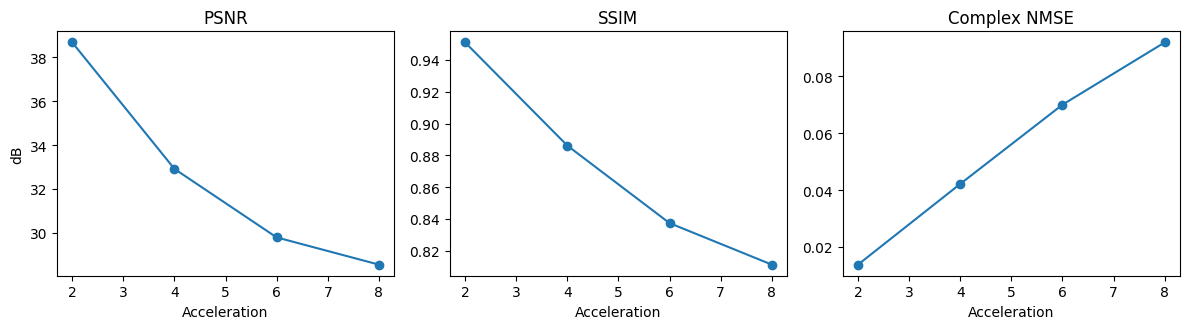

In [3]:
rows=[]
for rate in RATES:
    test=runs[rate][3]; zf=test['zero_filled']; result=test['swinmr']
    rows.append({'Rate':f'{rate}×','ZF PSNR':zf['psnr'],'SwinMR PSNR':result['psnr'],
                 'PSNR gain':result['psnr']-zf['psnr'],'ZF SSIM':zf['ssim'],
                 'SwinMR SSIM':result['ssim'],'Complex NMSE':result['nmse'],
                 'Residual':result['measurement_residual'],'Seconds/slice':result['seconds_per_slice']})
show_table(rows,[(key,key) for key in rows[0]])
fig,axes=plt.subplots(1,3,figsize=(12,3.4))
axes[0].plot(RATES,[row['SwinMR PSNR'] for row in rows],marker='o'); axes[0].set(title='PSNR',xlabel='Acceleration',ylabel='dB')
axes[1].plot(RATES,[row['SwinMR SSIM'] for row in rows],marker='o'); axes[1].set(title='SSIM',xlabel='Acceleration')
axes[2].plot(RATES,[row['Complex NMSE'] for row in rows],marker='o'); axes[2].set(title='Complex NMSE',xlabel='Acceleration')
plt.tight_layout(); plt.show()

## Training trajectories

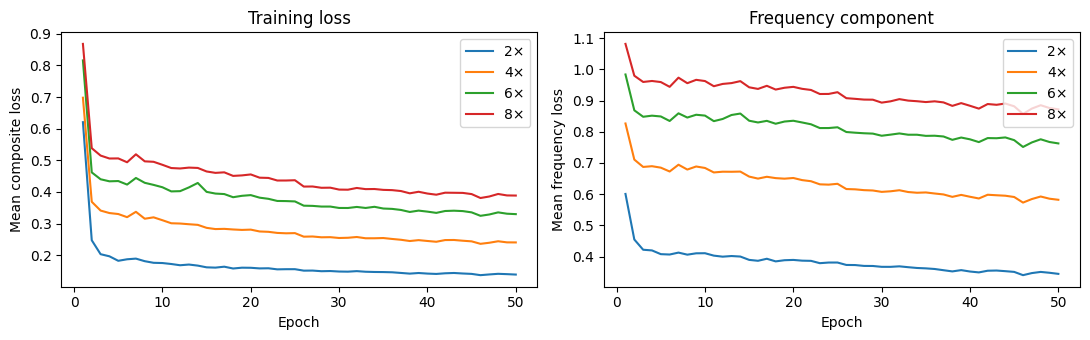

In [4]:
pattern=re.compile(r'epoch_complete=(\d+)/\d+ step=(\d+) mean_loss=([0-9.eE+-]+) mean_coil_image_charbonnier=([0-9.eE+-]+) mean_coil_kspace_charbonnier=([0-9.eE+-]+) mean_perceptual=([0-9.eE+-]+)')
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for rate in RATES:
    run=runs[rate][0]
    records=[match.groups() for line in (run/'train.log').read_text().splitlines() if (match:=pattern.search(line))]
    records=list({int(row[0]):row for row in records}.values()); records.sort(key=lambda row:int(row[0]))
    epochs=[int(row[0]) for row in records]
    axes[0].plot(epochs,[float(row[2]) for row in records],label=f'{rate}×')
    axes[1].plot(epochs,[float(row[4]) for row in records],label=f'{rate}×')
axes[0].set(xlabel='Epoch',ylabel='Mean composite loss',title='Training loss')
axes[1].set(xlabel='Epoch',ylabel='Mean frequency loss',title='Frequency component')
for axis in axes: axis.legend()
plt.tight_layout(); plt.show()

## Matched reconstruction comparison

Sample: file_brain_AXT1POST_203_6000889:7 (test slice closest to median 4x SwinMR PSNR gain)


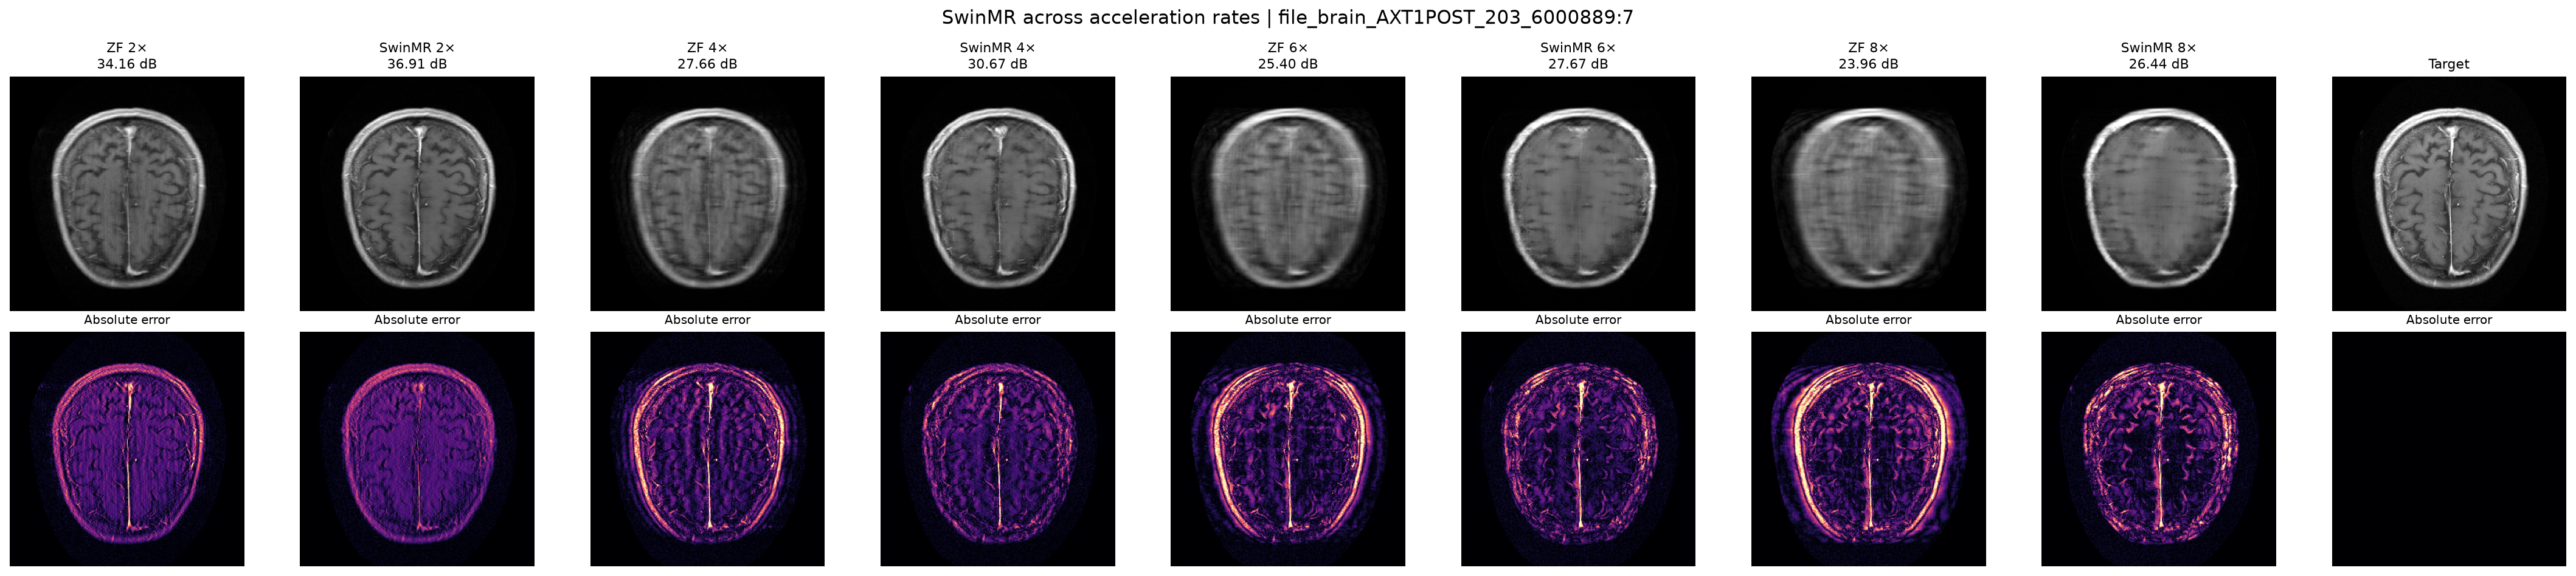

State,PSNR,SSIM,NMSE
ZF 2×,34.1552,0.9230,0.0126
SwinMR 2×,36.9109,0.9432,0.0074
ZF 4×,27.6563,0.8049,0.0491
SwinMR 4×,30.6722,0.8742,0.0282
ZF 6×,25.4033,0.7349,0.0807
SwinMR 6×,27.6709,0.7959,0.0529
ZF 8×,23.9645,0.6852,0.1105
SwinMR 8×,26.4410,0.7668,0.0689


In [5]:
print(f"Sample: {figure_metadata['sample_id']} ({figure_metadata['selection_reason']})")
display(Image(filename=str(ROOT/'results/swinmr_evaluation/qualitative/all_rate_comparison.png'),width=3000))
rows=[{'State':name,'PSNR':values['psnr'],'SSIM':values['ssim'],'NMSE':values['nmse']}
      for name,values in figure_metadata['metrics'].items()]
show_table(rows,[(key,key) for key in rows[0]])

## Interpretation

- Each acceleration rate uses independently trained weights and independently
  selected validation checkpoints.
- Quality is expected to decrease as acceleration rises because fewer phase-encoding
  measurements are retained.
- SwinMR has no explicit acquired-sample replacement or CG-SENSE layer; its reported
  residual therefore measures a genuine architectural tradeoff.
- Timing is system-dependent and is descriptive of this two-GPU workstation.

## Reproducibility artifacts

In [6]:
rows=[]
for rate in RATES:
    run,selection,test_dir,test=runs[rate]
    rows.extend([
        {'Rate':f'{rate}×','Artifact':'Selected checkpoint','Path':selection['checkpoint']},
        {'Rate':f'{rate}×','Artifact':'Test summary','Path':str(test_dir/'summary.json')},
        {'Rate':f'{rate}×','Artifact':'Slice metrics','Path':str(test_dir/'slice_metrics.jsonl')},
    ])
show_table(rows,[(key,key) for key in rows[0]],precision=0)

Rate,Artifact,Path
2×,Selected checkpoint,/data/ms_safari/david_agyei/nyu-dataset/derived/swinmr_pi_complex_2x/checkpoint-epoch-050-step-0011950.pt
2×,Test summary,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_2x/evaluation/test/step-0011950/summary.json
2×,Slice metrics,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_2x/evaluation/test/step-0011950/slice_metrics.jsonl
4×,Selected checkpoint,/data/ms_safari/david_agyei/nyu-dataset/derived/swinmr_pi_complex_4x/checkpoint-epoch-050-step-0011950.pt
4×,Test summary,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_4x/evaluation/test/step-0011950/summary.json
4×,Slice metrics,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_4x/evaluation/test/step-0011950/slice_metrics.jsonl
6×,Selected checkpoint,/data/ms_safari/david_agyei/nyu-dataset/derived/swinmr_pi_complex_6x/checkpoint-epoch-050-step-0011950.pt
6×,Test summary,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_6x/evaluation/test/step-0011950/summary.json
6×,Slice metrics,/data/david_agyei/nyu-dataset/derived/swinmr_pi_complex_6x/evaluation/test/step-0011950/slice_metrics.jsonl
8×,Selected checkpoint,/data/ms_safari/david_agyei/nyu-dataset/derived/swinmr_pi_complex_8x/checkpoint-epoch-050-step-0011950.pt
